<a href="https://colab.research.google.com/github/tn652006-droid/MachineLearning/blob/main/Tuan3/BTOL/ML_T3_BTVN_B4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Kich thuoc du lieu: (150, 4)
Cac loai hoa: ['setosa' 'versicolor' 'virginica']
So gia tri thieu: 0

TY LE: 80 / 20
So mau train: 120
So mau test: 30
Train Accuracy: 0.9833
Test Accuracy: 0.9667

Ma tran nham lan:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Bao cao phan loai:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



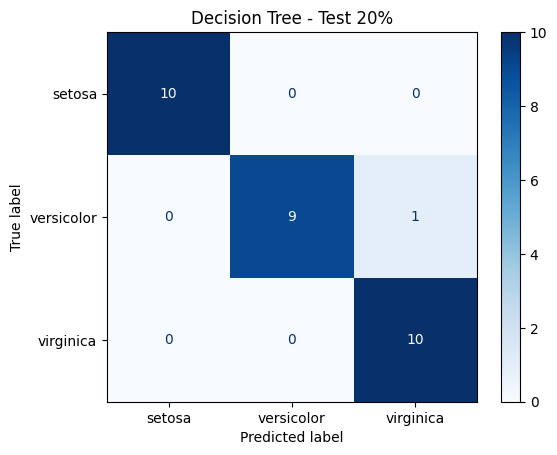


TY LE: 70 / 30
So mau train: 105
So mau test: 45
Train Accuracy: 0.981
Test Accuracy: 0.9778

Ma tran nham lan:
[[15  0  0]
 [ 0 14  1]
 [ 0  0 15]]

Bao cao phan loai:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.93      0.97        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



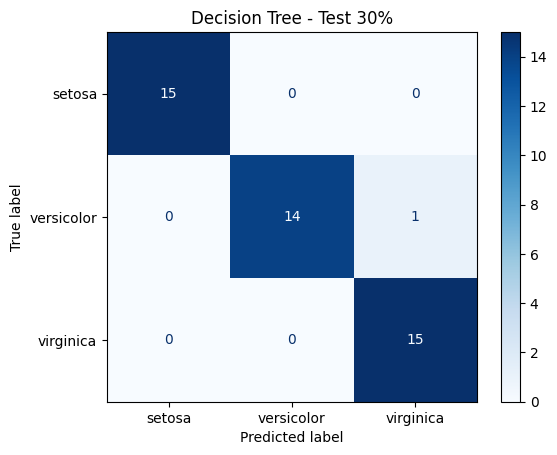


TY LE: 60 / 40
So mau train: 90
So mau test: 60
Train Accuracy: 0.9778
Test Accuracy: 0.9833

Ma tran nham lan:
[[20  0  0]
 [ 0 19  1]
 [ 0  0 20]]

Bao cao phan loai:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        20
  versicolor       1.00      0.95      0.97        20
   virginica       0.95      1.00      0.98        20

    accuracy                           0.98        60
   macro avg       0.98      0.98      0.98        60
weighted avg       0.98      0.98      0.98        60



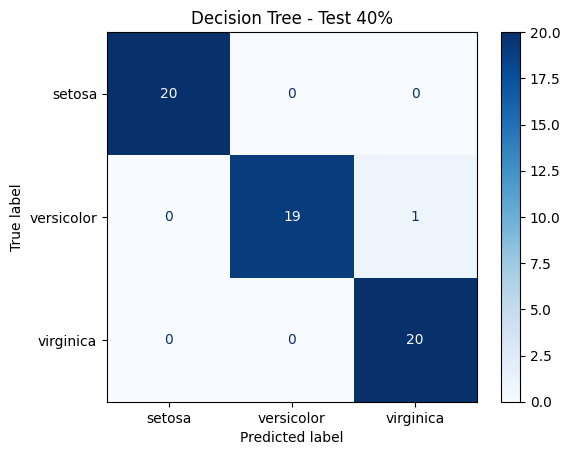


===== BANG SO SANH KET QUA =====
Ty le Train/Test  Train Accuracy  Test Accuracy  So nut  Do sau
           80/20        0.983333       0.966667       9       3
           70/30        0.980952       0.977778       9       3
           60/40        0.977778       0.983333       9       3


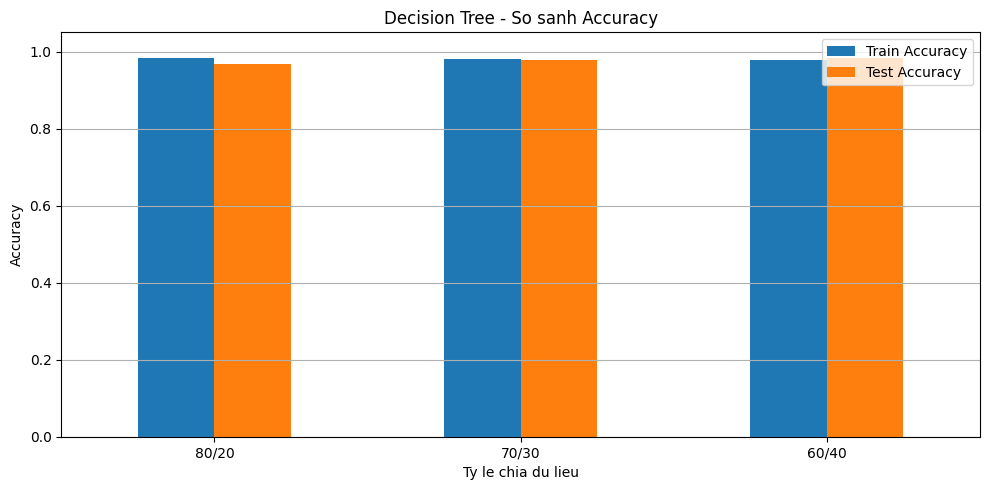

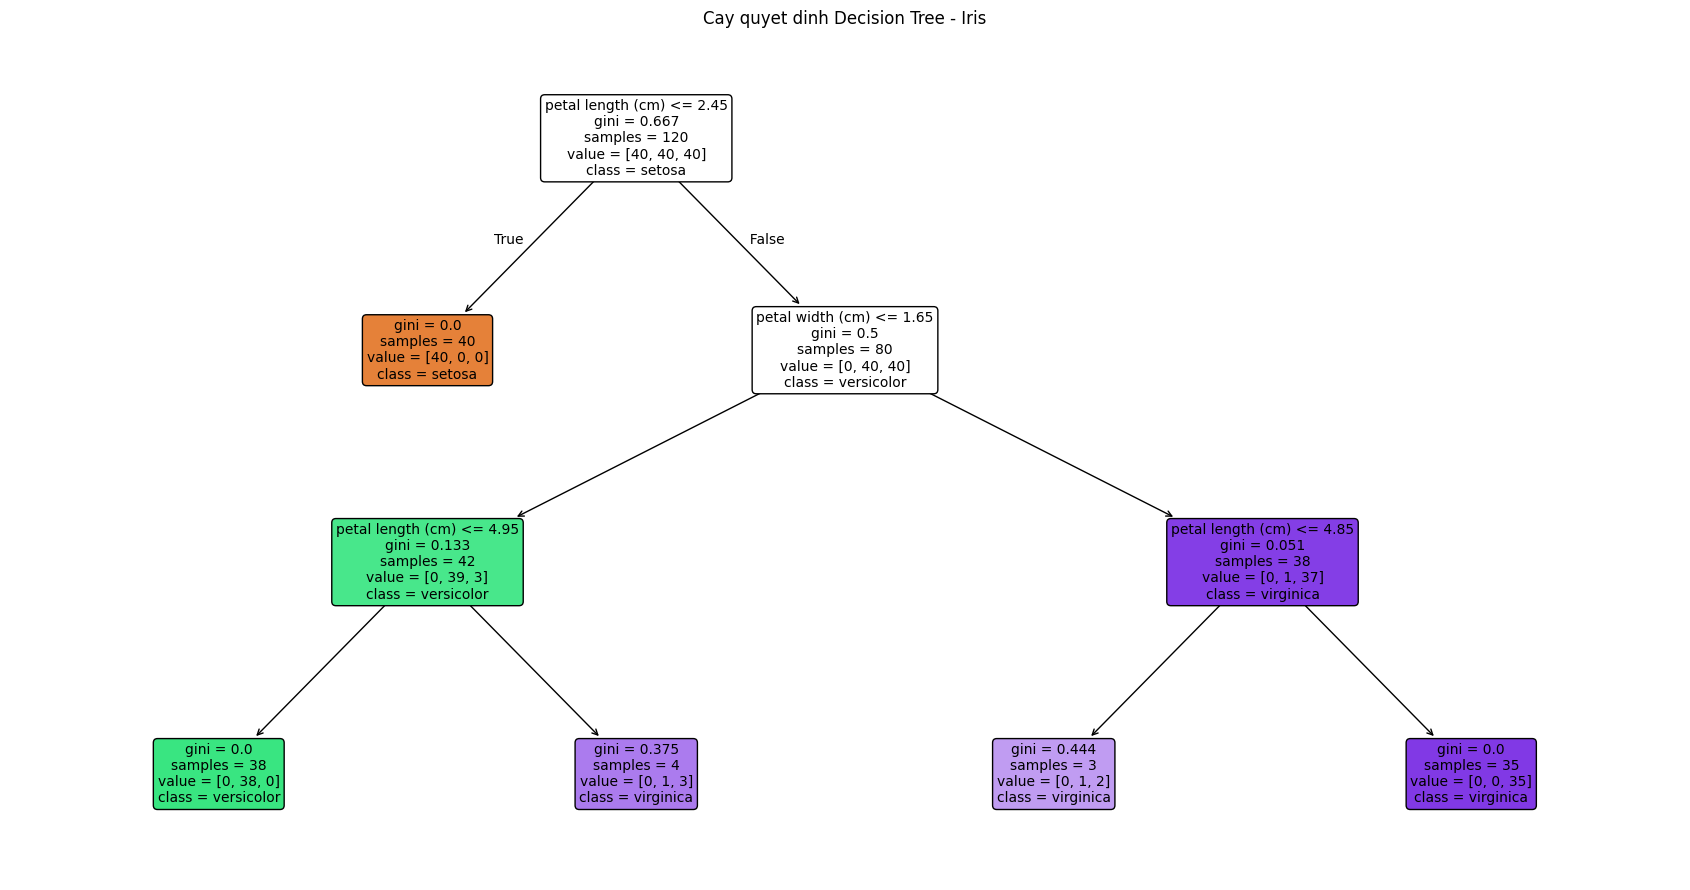


===== KET LUAN =====
Ty le co Accuracy cao nhat trong thu nghiem: 60/40
Test Accuracy: 0.9833
Do sau cay: 3
So nut: 9


In [3]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ==========================================
# 1. NAP DU LIEU IRIS
# ==========================================
iris = load_iris()
X = iris.data
y = iris.target

print("Kich thuoc du lieu:", X.shape)
print("Cac loai hoa:", iris.target_names)
print("So gia tri thieu:", pd.DataFrame(X).isna().sum().sum())

# ==========================================
# 2. THU NGHIEM 3 TY LE CHIA DU LIEU
# ==========================================
results = []

for test_size in [0.2, 0.3, 0.4]:

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=42,
        stratify=y
    )

    # ======================================
    # 3. TAO VA HUAN LUYEN DECISION TREE
    # ======================================
    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=3,
        random_state=42
    )

    model.fit(X_train, y_train)

    # Du doan
    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    # Danh gia
    acc_train = accuracy_score(y_train, pred_train)
    acc_test = accuracy_score(y_test, pred_test)

    results.append({
        "Ty le Train/Test": f"{int((1-test_size)*100)}/{int(test_size*100)}",
        "Train Accuracy": acc_train,
        "Test Accuracy": acc_test,
        "So nut": model.tree_.node_count,
        "Do sau": model.get_depth()
    })

    print("\n====================================")
    print("TY LE:", int((1-test_size)*100),
          "/", int(test_size*100))
    print("So mau train:", len(X_train))
    print("So mau test:", len(X_test))
    print("Train Accuracy:", round(acc_train, 4))
    print("Test Accuracy:", round(acc_test, 4))

    # Ma tran nham lan
    print("\nMa tran nham lan:")
    print(confusion_matrix(y_test, pred_test))

    # Bao cao phan loai
    print("\nBao cao phan loai:")
    print(classification_report(
        y_test, pred_test,
        target_names=iris.target_names,
        zero_division=0
    ))

    # Ve ma tran nham lan
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        pred_test,
        display_labels=iris.target_names,
        cmap="Blues"
    )
    plt.title(
        f"Decision Tree - Test {int(test_size*100)}%"
    )
    plt.show()

# ==========================================
# 4. BANG SO SANH CAC TY LE
# ==========================================
df = pd.DataFrame(results)

print("\n===== BANG SO SANH KET QUA =====")
print(df.to_string(index=False))

# ==========================================
# 5. BIEU DO SO SANH ACCURACY
# ==========================================
df.plot(
    x="Ty le Train/Test",
    y=["Train Accuracy", "Test Accuracy"],
    kind="bar",
    figsize=(10, 5)
)

plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.xlabel("Ty le chia du lieu")
plt.title("Decision Tree - So sanh Accuracy")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()

# ==========================================
# 6. VE CAY QUYET DINH CHO TY LE 80/20
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)

plt.figure(figsize=(17, 9))

plot_tree(
    model,
    feature_names=iris.feature_names,
    class_names=list(iris.target_names),
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Cay quyet dinh Decision Tree - Iris")
plt.tight_layout()
plt.show()

# ==========================================
# 7. TONG KET
# ==========================================
best = df.loc[df["Test Accuracy"].idxmax()]

print("\n===== KET LUAN =====")
print("Ty le co Accuracy cao nhat trong thu nghiem:",
      best["Ty le Train/Test"])
print("Test Accuracy:", round(best["Test Accuracy"], 4))
print("Do sau cay:", best["Do sau"])
print("So nut:", best["So nut"])
